# Load libraries

In [ ]:
import sys
github_repo_url = "https://github.com/AnnaEls/HAADF-STEM-image-denoising.git"
!git clone {github_repo_url}
sys.path.append('/content/HAADF-STEM-image-denoising')

Cloning into 'HAADF-STEM-image-denoising'...
remote: Enumerating objects: 1658, done.
remote: Counting objects: 100% (159/159), done.
remote: Compressing objects: 100% (157/157), done.
remote: Total 1658 (delta 63), reused 2 (delta 2), pack-reused 1499 (from 1)
Receiving objects: 100% (1658/1658), 168.13 MiB | 15.36 MiB/s, done.
Resolving deltas: 100% (738/738), done.
Updating files: 100% (319/319), done.


In [ ]:
!pip install atomap
!pip install hyperspy
import atomap.api as am
import hyperspy.api as hs

import pandas as pd
import numpy as np
from Analysis.gaussian_detection_atomap import find_atoms, compare_sublattices_with_lattice_fp_classification, plot_atom_classification

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.5/42.5 kB 992.2 kB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.2/45.2 kB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 868.9/868.9 kB 14.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 68.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 51.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 603.8/603.8 kB 24.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 351.9/351.9 kB 20.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 52.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.1/5.1 MB 18.8 MB/s eta 0:00:00


/usr/local/lib/python3.13/dist-packages/hyperspy/misc/_utils.py:1590: VisibleDeprecationWarning: Importing `LazyComplexSignal1D` from `hyperspy._signals.complex_signal1d` is deprecated and will be removed in the HyperSpy 3.0 release. Import it from `hyperspy.signals` instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/hyperspy/misc/_utils.py:1590: VisibleDeprecationWarning: Importing `LazySignal1D` from `hyperspy._signals.signal1d` is deprecated and will be removed in the HyperSpy 3.0 release. Import it from `hyperspy.signals` instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/hyperspy/misc/_utils.py:1590: VisibleDeprecationWarning: Importing `LazySignal1D` from `hyperspy._signals.signal1d` is deprecated and will be removed in the HyperSpy 3.0 release. Import it from `hyperspy.signals` instead.
  warnings.warn(


In [ ]:
import tifffile
import numpy as np
import matplotlib.pyplot as plt

from skimage.metrics import peak_signal_noise_ratio as psnr

from Utilities.Utils import convert
from Analysis.FFT_analysis import estimate_real_lattice_vectors_fft
from Analysis.correlation_map import pearson_correlation_map
from Analysis.gaussian_detection_atomap import find_atoms, sublattice_to_xy, estimate_hexagonal_lattice_vectors_from_points, generate_lattice_positions, keep_lattice_inside_image, find_vacancies_from_lattice, plot_vacancies, match_reference_and_noisy, classify_false_positives_by_lattice_symmetry
from scipy.spatial import cKDTree

from matplotlib.lines import Line2D
from matplotlib.patches import RegularPolygon
from matplotlib.legend_handler import HandlerPatch

In [ ]:
def identify_vacancies(sublattice,sublattice_clean, image):
  sublattice_xy_clean = sublattice_to_xy(sublattice_clean)
  a,b = estimate_hexagonal_lattice_vectors_from_points(xy=sublattice_xy_clean, neighbor_radius=25, angle_tolerance_deg=15)
  lattice_xy_clean = generate_lattice_positions(xy=sublattice_xy_clean, a=a, b=b, image_shape=image.shape, margin=20)
  lattice_inner = keep_lattice_inside_image(lattice_xy_clean, image, margin=10)
  vacancy_xy, occupied_xy, distances = find_vacancies_from_lattice(sublattice, lattice_inner, vacancy_tolerance=10.0)
  return vacancy_xy

In [ ]:
def process_image(image, sublattice_clean, separation, match_tolerance, lattice_tolerance, neighbor_radius):
  s = hs.signals.Signal2D(image)
  sublattice = find_atoms(s, separation = separation,  plot = True)
  plt.show()
  atom_data = []
  for atom in sublattice.atom_list:
    atom_data.append({
        'x': atom.pixel_x,
        'y': atom.pixel_y,
        'sx': atom.sigma_x,
        'sy': atom.sigma_y,
        'r': atom.rotation,
        'e': atom.ellipticity,
        'amplitude_gaussian': atom.amplitude_gaussian
       })
  results = compare_sublattices_with_lattice_fp_classification(
        sublattice_clean,
        sublattice,
        image_shape=image.shape,
        match_tolerance=match_tolerance,
        lattice_tolerance=lattice_tolerance,
        neighbor_radius=neighbor_radius)
  plot_atom_classification(image, sublattice_clean, sublattice, results)

  vacancy_xy = identify_vacancies(sublattice, image)
  clean_vacancy_tree = cKDTree(vacancy_xy_clean)
  distances, indices = clean_vacancy_tree.query(vacancy_xy)
  coinciding_noisy_vacancies = vacancy_xy[distances <= MATCH_TOLERANCE]
  false_positive_vacancies = vacancy_xy[distances > MATCH_TOLERANCE]

  bad_fp_coords = [fp['false_positive_xy'] for fp in results['bad_false_positives']]
  bad_fp_coords = np.array(bad_fp_coords)
  if len(bad_fp_coords) > 0:
    distances, indices = clean_vacancy_tree.query(bad_fp_coords)
    coinciding_false_positives = bad_fp_coords[distances <= MATCH_TOLERANCE]
  else:
    coinciding_false_positives = []
  plot_vacancies(image, sublattice_clean, coinciding_noisy_vacancies, coinciding_false_positives, false_positive_vacancies, s_v=650,show_atoms=True)

  return  coinciding_noisy_vacancies, coinciding_false_positives, false_positive_vacancies, results["num_true_positives"],  results["num_false_positives"]

In [ ]:
# Redefine process_image to fix the argument mismatch when calling identify_vacancies
def process_image(image, sublattice_clean, separation, match_tolerance, lattice_tolerance, neighbor_radius):
  s = hs.signals.Signal2D(image)
  sublattice = find_atoms(s, separation = separation,  plot = True)
  plt.show()
  atom_data = []
  for atom in sublattice.atom_list:
    atom_data.append({
        'x': atom.pixel_x,
        'y': atom.pixel_y,
        'sx': atom.sigma_x,
        'sy': atom.sigma_y,
        'r': atom.rotation,
        'e': atom.ellipticity,
        'amplitude_gaussian': atom.amplitude_gaussian
       })
  results = compare_sublattices_with_lattice_fp_classification(
        sublattice_clean,
        sublattice,
        image_shape=image.shape,
        match_tolerance=match_tolerance,
        lattice_tolerance=lattice_tolerance,
        neighbor_radius=neighbor_radius)
  plot_atom_classification(image, sublattice_clean, sublattice, results)

  # Fixed: Pass sublattice_clean as the second argument
  vacancy_xy = identify_vacancies(sublattice, sublattice_clean, image)
  clean_vacancy_tree = cKDTree(vacancy_xy_clean)
  distances, indices = clean_vacancy_tree.query(vacancy_xy)
  coinciding_noisy_vacancies = vacancy_xy[distances <= match_tolerance]
  false_positive_vacancies = vacancy_xy[distances > match_tolerance]

  bad_fp_coords = [fp['false_positive_xy'] for fp in results['bad_false_positives']]
  bad_fp_coords = np.array(bad_fp_coords)
  if len(bad_fp_coords) > 0:
    distances, indices = clean_vacancy_tree.query(bad_fp_coords)
    coinciding_false_positives = bad_fp_coords[distances <= match_tolerance]
  else:
    coinciding_false_positives = []
  plot_vacancies(image, sublattice, coinciding_noisy_vacancies, coinciding_false_positives, false_positive_vacancies, s_v=650, show_atoms=True)

  return coinciding_noisy_vacancies, coinciding_false_positives, false_positive_vacancies, results["num_true_positives"], results["num_false_positives"]


In [ ]:
def plot_vacancies_paper(
    ax,
    clean_sublattice,
    vacancy_xy,
    false_pos_xy,
    false_pos_vac_xy,
    s_v = 250,
    s_a = 35,
    show_atoms=True
):
    if hasattr(image, "data"):
        img = image.data
    else:
        img = image

    atom_xy = sublattice_to_xy(clean_sublattice)

    ax.imshow(img, cmap="gray")

    if show_atoms:
        ax.scatter(
            atom_xy[:, 0],
            atom_xy[:, 1],
            marker="x",
            s=s_a,
            c="lime",
            linewidths=1.3,
            label="Detected atoms"
        )

    if len(vacancy_xy) > 0:
        ax.scatter(
            vacancy_xy[:, 0],
            vacancy_xy[:, 1],
            s=s_v,
            facecolors="none",
            edgecolors="lime",
            linewidths=2.5,
            label="Vacancy"
        )
    if len(false_pos_xy) > 0:
        ax.scatter(
            false_pos_xy[:, 0],
            false_pos_xy[:, 1],
            s=s_v,
            facecolors="none",
            edgecolors="red",
            linewidths=2.5,
            label="False positive"
        )
    if len(false_pos_vac_xy) > 0:
        ax.scatter(
            false_pos_vac_xy[:, 0],
            false_pos_vac_xy[:, 1],
            s=s_v,
            facecolors="none",
            edgecolors="orange",
            linewidths=2.5,
            label="False positive vacancy"
        )

    ax.axis("off")



# Doses

In [ ]:
doses = [1000000.0, 500000.0, 250000.0, 100000.0, 50000.0, 25000.0]


In [ ]:
SEPARATION = 5
MATCH_TOLERANCE=5.0,
LATTICE_TOLERANCE=5.0,
NEIGHBOR_RADIUS=35

# Processing clean image

Center of mass:   0%|          | 0/609 [00:00<?, ?it/s]

Gaussian fitting:   0%|          | 0/609 [00:00<?, ?it/s]

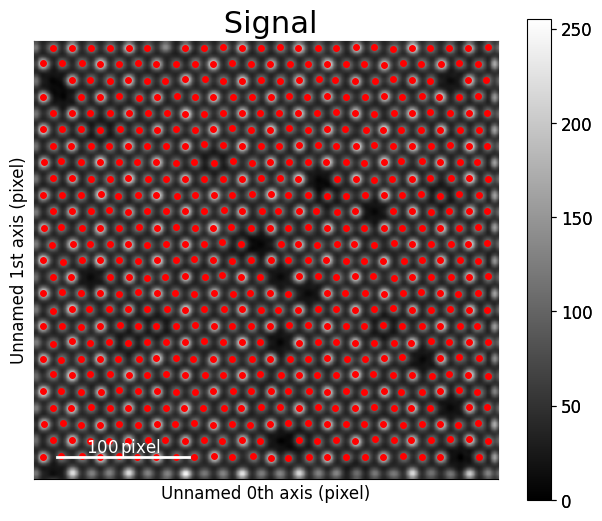

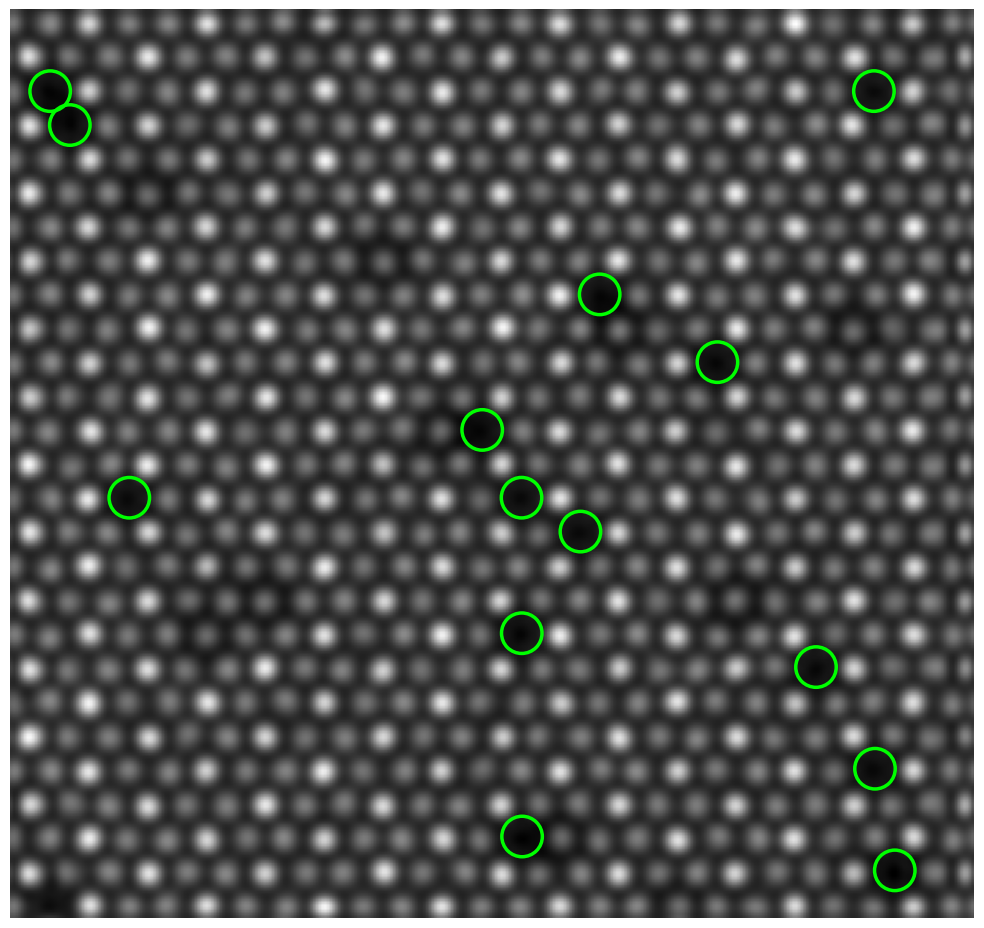

In [ ]:
dataset_path = '/content/HAADF-STEM-image-denoising/Datasets/DATASET_graphene_vacancies/'
path_to_clean_image = dataset_path + 'graphene-ground_truth_interp_0.1_dose_no_noise.tif'
clean_image = convert(tifffile.imread(path_to_clean_image))
s = hs.signals.Signal2D(clean_image)
sublattice_clean = find_atoms(s, separation = SEPARATION, plot = True)
vacancy_xy_clean = identify_vacancies(sublattice_clean, sublattice_clean, clean_image)
plot_vacancies(clean_image,sublattice_clean,vacancy_xy_clean, false_pos_xy = [], false_pos_vac_xy = [], s_v = 850, show_atoms=False)

# Hybrid model (Fourier)

In [ ]:
results_hybrid = []
rows = []
for dose in doses:
    print("Dose:" + str(dose))
    output_path = f'/content/HAADF-STEM-image-denoising/Datasets/DATASET_graphene_vacancies/denoised_hybrid/'
    image_path = output_path + f'graphene-jittered_interp_0.1_dose_{dose}_denoised_hybrid.tif'
    image = convert(tifffile.imread(image_path))
    results = process_image(image, sublattice_clean, SEPARATION, MATCH_TOLERANCE, LATTICE_TOLERANCE, NEIGHBOR_RADIUS)
    results_hybrid.append(results)
    rows.append({"dose": dose, "TP_atoms": results[3],  "FP_atoms": results[4], "TP_vac": len(results[0]), "FP_vac": len(results[2])})

In [ ]:
N_TP = len(sublattice_clean.atom_list)
df = pd.DataFrame(rows)

N_atoms = N_TP
N_vac = 14

# False negatives
df["FN_atoms"] = N_atoms - df["TP_atoms"]
df["FN_vac"] = N_vac - df["TP_vac"]

# Precision
df["Precision_atoms"] = np.round(
    df["TP_atoms"] / (df["TP_atoms"] + df["FP_atoms"]),
    2
)

df["Precision_vac"] = np.round(
    df["TP_vac"] / (df["TP_vac"] + df["FP_vac"]),
    2
)

# Recall
df["Recall_atoms"] = np.round(
    df["TP_atoms"] / (df["TP_atoms"] + df["FN_atoms"]),
    2
)

df["Recall_vac"] = np.round(
    df["TP_vac"] / (df["TP_vac"] + df["FN_vac"]),
    2
)

# F1 scores
df["F1_atoms"] = np.round(
    2 * df["TP_atoms"] /
    (2 * df["TP_atoms"] + df["FP_atoms"] + df["FN_atoms"]),
    2
)

df["F1_vac"] = np.round(
    2 * df["TP_vac"] /
    (2 * df["TP_vac"] + df["FP_vac"] + df["FN_vac"]),
    2
)

display(df)

,dose,TP_atoms,FP_atoms,TP_vac,FP_vac,FN_atoms,FN_vac,Precision_atoms,Precision_vac,Recall_atoms,Recall_vac,F1_atoms,F1_vac
0,1000000.0,609,1,14,0,0,0,1.00,1.00,1.00,1.00,1.00,1.00
1,500000.0,609,1,14,0,0,0,1.00,1.00,1.00,1.00,1.00,1.00
2,250000.0,609,12,4,0,0,10,0.98,1.00,1.00,0.29,0.99,0.44
3,100000.0,606,16,0,0,3,14,0.97,NaN,1.00,0.00,0.98,0.00
4,50000.0,599,20,0,3,10,14,0.97,0.00,0.98,0.00,0.98,0.00
5,25000.0,559,42,1,14,50,13,0.93,0.07,0.92,0.07,0.92,0.07


# Hybrid model (CNN)

In [ ]:
results_hybrid_cnn = []
rows = []
for dose in doses:
    print("Dose:" + str(dose))
    output_path = f'/content/HAADF-STEM-image-denoising/Datasets/DATASET_graphene_vacancies/denoised_hybrid_cnn/'
    image_path = output_path + f'graphene-jittered_interp_0.1_dose_{dose}_denoised_hybrid_cnn.tif'
    image = convert(tifffile.imread(image_path))
    results = process_image(image, sublattice_clean, SEPARATION, MATCH_TOLERANCE, LATTICE_TOLERANCE, NEIGHBOR_RADIUS)
    results_hybrid_cnn.append(results)
    rows.append({"dose": dose, "TP_atoms": results[3],  "FP_atoms": results[4], "TP_vac": len(results[0]), "FP_vac": len(results[2])})

In [ ]:
N_TP = len(sublattice_clean.atom_list)
df = pd.DataFrame(rows)

N_atoms = N_TP
N_vac = 14

# False negatives
df["FN_atoms"] = N_atoms - df["TP_atoms"]
df["FN_vac"] = N_vac - df["TP_vac"]

# Precision
df["Precision_atoms"] = np.round(
    df["TP_atoms"] / (df["TP_atoms"] + df["FP_atoms"]),
    2
)

df["Precision_vac"] = np.round(
    df["TP_vac"] / (df["TP_vac"] + df["FP_vac"]),
    2
)

# Recall
df["Recall_atoms"] = np.round(
    df["TP_atoms"] / (df["TP_atoms"] + df["FN_atoms"]),
    2
)

df["Recall_vac"] = np.round(
    df["TP_vac"] / (df["TP_vac"] + df["FN_vac"]),
    2
)

# F1 scores
df["F1_atoms"] = np.round(
    2 * df["TP_atoms"] /
    (2 * df["TP_atoms"] + df["FP_atoms"] + df["FN_atoms"]),
    2
)

df["F1_vac"] = np.round(
    2 * df["TP_vac"] /
    (2 * df["TP_vac"] + df["FP_vac"] + df["FN_vac"]),
    2
)

display(df)

,dose,TP_atoms,FP_atoms,TP_vac,FP_vac,FN_atoms,FN_vac,Precision_atoms,Precision_vac,Recall_atoms,Recall_vac,F1_atoms,F1_vac
0,1000000.0,609,1,14,0,0,0,1.00,1.00,1.00,1.00,1.00,1.00
1,500000.0,608,2,14,1,1,0,1.00,0.93,1.00,1.00,1.00,0.97
2,250000.0,608,3,12,0,1,2,1.00,1.00,1.00,0.86,1.00,0.92
3,100000.0,594,61,3,2,15,11,0.91,0.60,0.98,0.21,0.94,0.32
4,50000.0,539,202,1,4,70,13,0.73,0.20,0.89,0.07,0.80,0.11
5,25000.0,366,319,3,28,243,11,0.53,0.10,0.60,0.21,0.57,0.13


# Lobato

In [ ]:
results_lobato = []
rows = []
for dose in doses:
    print("Dose:" + str(dose))
    output_path = f'/content/HAADF-STEM-image-denoising/Datasets/DATASET_graphene_vacancies/denoised_lobato/'
    image_path = output_path + f'graphene-jittered_interp_0.1_dose_{dose}_restored_sfr_hrstem.tif'
    image = convert(tifffile.imread(image_path))
    results = process_image(image, sublattice_clean, SEPARATION, MATCH_TOLERANCE, LATTICE_TOLERANCE, NEIGHBOR_RADIUS)
    results_lobato.append(results)
    rows.append({"dose": dose, "TP_atoms": results[3],  "FP_atoms": results[4], "TP_vac": len(results[0]), "FP_vac": len(results[2])})

In [ ]:
N_TP = len(sublattice_clean.atom_list)
df = pd.DataFrame(rows)

N_atoms = N_TP
N_vac = 14

# False negatives
df["FN_atoms"] = N_atoms - df["TP_atoms"]
df["FN_vac"] = N_vac - df["TP_vac"]

# Precision
df["Precision_atoms"] = np.round(
    df["TP_atoms"] / (df["TP_atoms"] + df["FP_atoms"]),
    2
)

df["Precision_vac"] = np.round(
    df["TP_vac"] / (df["TP_vac"] + df["FP_vac"]),
    2
)

# Recall
df["Recall_atoms"] = np.round(
    df["TP_atoms"] / (df["TP_atoms"] + df["FN_atoms"]),
    2
)

df["Recall_vac"] = np.round(
    df["TP_vac"] / (df["TP_vac"] + df["FN_vac"]),
    2
)

# F1 scores
df["F1_atoms"] = np.round(
    2 * df["TP_atoms"] /
    (2 * df["TP_atoms"] + df["FP_atoms"] + df["FN_atoms"]),
    2
)

df["F1_vac"] = np.round(
    2 * df["TP_vac"] /
    (2 * df["TP_vac"] + df["FP_vac"] + df["FN_vac"]),
    2
)

display(df)

,dose,TP_atoms,FP_atoms,TP_vac,FP_vac,FN_atoms,FN_vac,Precision_atoms,Precision_vac,Recall_atoms,Recall_vac,F1_atoms,F1_vac
0,1000000.0,609,11,4,0,0,10,0.98,1.00,1.00,0.29,0.99,0.44
1,500000.0,609,14,1,0,0,13,0.98,1.00,1.00,0.07,0.99,0.13
2,250000.0,609,15,0,0,0,14,0.98,NaN,1.00,0.00,0.99,0.00
3,100000.0,608,15,0,0,1,14,0.98,NaN,1.00,0.00,0.99,0.00
4,50000.0,600,16,0,0,9,14,0.97,NaN,0.99,0.00,0.98,0.00
5,25000.0,450,93,5,54,159,9,0.83,0.08,0.74,0.36,0.78,0.14


# Pinto

In [ ]:
results_pinto = []
rows = []
for dose in doses:
    print("Dose:" + str(dose))
    output_path = f'/content/HAADF-STEM-image-denoising/Datasets/DATASET_graphene_vacancies/denoised_pinto/'
    image_path = output_path + f'graphene-jittered_interp_0.1_dose_{dose}_denoised_pinto.tif'
    image = convert(tifffile.imread(image_path))
    results = process_image(image, sublattice_clean, SEPARATION, MATCH_TOLERANCE, LATTICE_TOLERANCE, NEIGHBOR_RADIUS)
    results_pinto.append(results)
    rows.append({"dose": dose, "TP_atoms": results[3],  "FP_atoms": results[4], "TP_vac": len(results[0]), "FP_vac": len(results[2])})

In [ ]:
N_TP = len(sublattice_clean.atom_list)
df = pd.DataFrame(rows)

N_atoms = N_TP
N_vac = 14

# False negatives
df["FN_atoms"] = N_atoms - df["TP_atoms"]
df["FN_vac"] = N_vac - df["TP_vac"]

# Precision
df["Precision_atoms"] = np.round(
    df["TP_atoms"] / (df["TP_atoms"] + df["FP_atoms"]),
    2
)

df["Precision_vac"] = np.round(
    df["TP_vac"] / (df["TP_vac"] + df["FP_vac"]),
    2
)

# Recall
df["Recall_atoms"] = np.round(
    df["TP_atoms"] / (df["TP_atoms"] + df["FN_atoms"]),
    2
)

df["Recall_vac"] = np.round(
    df["TP_vac"] / (df["TP_vac"] + df["FN_vac"]),
    2
)

# F1 scores
df["F1_atoms"] = np.round(
    2 * df["TP_atoms"] /
    (2 * df["TP_atoms"] + df["FP_atoms"] + df["FN_atoms"]),
    2
)

df["F1_vac"] = np.round(
    2 * df["TP_vac"] /
    (2 * df["TP_vac"] + df["FP_vac"] + df["FN_vac"]),
    2
)

display(df)

,dose,TP_atoms,FP_atoms,TP_vac,FP_vac,FN_atoms,FN_vac,Precision_atoms,Precision_vac,Recall_atoms,Recall_vac,F1_atoms,F1_vac
0,1000000.0,603,15,0,0,6,14,0.98,NaN,0.99,0.00,0.98,0.00
1,500000.0,599,28,2,3,10,12,0.96,0.40,0.98,0.14,0.97,0.21
2,250000.0,580,138,2,4,29,12,0.81,0.33,0.95,0.14,0.87,0.20
3,100000.0,557,173,0,10,52,14,0.76,0.00,0.91,0.00,0.83,0.00
4,50000.0,518,308,0,11,91,14,0.63,0.00,0.85,0.00,0.72,0.00
5,25000.0,444,432,0,5,165,14,0.51,0.00,0.73,0.00,0.60,0.00


# UNIT NEW

In [ ]:
results_unit = []
rows = []
for dose in doses:
    print("Dose:" + str(dose))
    output_path = f'/content/HAADF-STEM-image-denoising/Datasets/DATASET_graphene_vacancies/denoised_unit_new/'
    image_path = output_path + f'graphene-jittered_interp_0.1_dose_{dose}_unit_aligned.tif'
    image = convert(tifffile.imread(image_path))
    results = process_image(image, sublattice_clean, SEPARATION, MATCH_TOLERANCE, LATTICE_TOLERANCE, NEIGHBOR_RADIUS)
    results_unit.append(results)
    rows.append({"dose": dose, "TP_atoms": results[3],  "FP_atoms": results[4], "TP_vac": len(results[0]), "FP_vac": len(results[2])})


In [ ]:
N_TP = len(sublattice_clean.atom_list)
df = pd.DataFrame(rows)

N_atoms = N_TP
N_vac = 14

# False negatives
df["FN_atoms"] = N_atoms - df["TP_atoms"]
df["FN_vac"] = N_vac - df["TP_vac"]

# Precision
df["Precision_atoms"] = np.round(
    df["TP_atoms"] / (df["TP_atoms"] + df["FP_atoms"]),
    2
)

df["Precision_vac"] = np.round(
    df["TP_vac"] / (df["TP_vac"] + df["FP_vac"]),
    2
)

# Recall
df["Recall_atoms"] = np.round(
    df["TP_atoms"] / (df["TP_atoms"] + df["FN_atoms"]),
    2
)

df["Recall_vac"] = np.round(
    df["TP_vac"] / (df["TP_vac"] + df["FN_vac"]),
    2
)

# F1 scores
df["F1_atoms"] = np.round(
    2 * df["TP_atoms"] /
    (2 * df["TP_atoms"] + df["FP_atoms"] + df["FN_atoms"]),
    2
)

df["F1_vac"] = np.round(
    2 * df["TP_vac"] /
    (2 * df["TP_vac"] + df["FP_vac"] + df["FN_vac"]),
    2
)

display(df)

,dose,TP_atoms,FP_atoms,TP_vac,FP_vac,FN_atoms,FN_vac,Precision_atoms,Precision_vac,Recall_atoms,Recall_vac,F1_atoms,F1_vac
0,1000000.0,572,0,14,28,37,0,1.00,0.33,0.94,1.00,0.97,0.50
1,500000.0,541,1,14,58,68,0,1.00,0.19,0.89,1.00,0.94,0.33
2,250000.0,521,6,13,69,88,1,0.99,0.16,0.86,0.93,0.92,0.27
3,100000.0,467,22,11,99,142,3,0.96,0.10,0.77,0.79,0.85,0.18
4,50000.0,419,59,13,87,190,1,0.88,0.13,0.69,0.93,0.77,0.23
5,25000.0,354,109,10,82,255,4,0.76,0.11,0.58,0.71,0.66,0.19


# Plotting

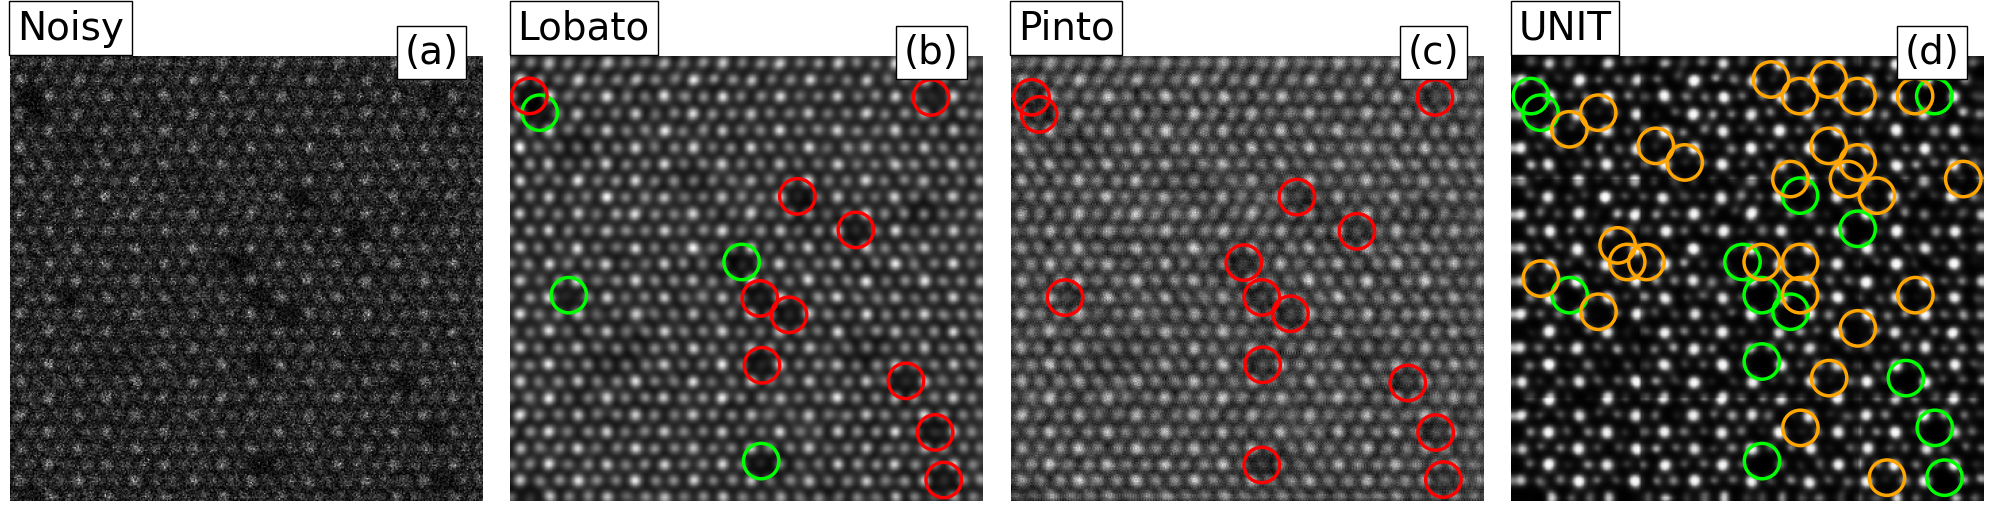

In [ ]:
dose = 1000000.0
k = 0
images = []
noisy_image_path = f"/content/HAADF-STEM-image-denoising/Datasets/DATASET_graphene_vacancies/graphene-jittered_interp_0.1_dose_{dose}.tif"
lobato_image_path = f"/content/HAADF-STEM-image-denoising/Datasets/DATASET_graphene_vacancies/denoised_lobato/graphene-jittered_interp_0.1_dose_{dose}_restored_sfr_hrstem.tif"
pinto_image_path = f"/content/HAADF-STEM-image-denoising/Datasets/DATASET_graphene_vacancies/denoised_pinto/graphene-jittered_interp_0.1_dose_{dose}_denoised_pinto.tif"
unit_image_path = f"/content/HAADF-STEM-image-denoising/Datasets/DATASET_graphene_vacancies/denoised_unit_new/graphene-jittered_interp_0.1_dose_{dose}_unit_aligned.tif"
hybrid_image_path = f"/content/HAADF-STEM-image-denoising/Datasets/DATASET_graphene_vacancies/denoised_hybrid/graphene-jittered_interp_0.1_dose_{dose}_denoised_hybrid.tif"
hybrid_cnn_image_path = f"/content/HAADF-STEM-image-denoising/Datasets/DATASET_graphene_vacancies/denoised_hybrid_cnn/graphene-jittered_interp_0.1_dose_{dose}_denoised_hybrid_cnn.tif"

images.append(convert(tifffile.imread(noisy_image_path)))
images.append(convert(tifffile.imread(lobato_image_path)))
images.append(convert(tifffile.imread(pinto_image_path)))
images.append(convert(tifffile.imread(unit_image_path)))
images.append(convert(tifffile.imread(hybrid_image_path)))
images.append(convert(tifffile.imread(hybrid_cnn_image_path)))

coinciding_noisy_vacancies = [results_lobato[k][0], results_pinto[k][0], results_unit[k][0], results_hybrid[k][0], results_hybrid_cnn[k][0]]
coinciding_false_positives = [results_lobato[k][1], results_pinto[k][1], results_unit[k][1], results_hybrid[k][1], results_hybrid_cnn[k][1]]
false_positive_vacancies = [results_lobato[k][2], results_pinto[k][2], results_unit[k][2], results_hybrid[k][2], results_hybrid_cnn[k][2]]

from matplotlib.lines import Line2D
n = len(images[:4])
sub = 1
models = ["Noisy", "Lobato", "Pinto", "UNIT"]
letters_img = ["(a)", "(b)", "(c)", "(d)",]

fig = plt.figure(
    figsize=(5*n, 5*sub),
    constrained_layout=True
)

gs = fig.add_gridspec(sub, n )

plt.rcParams.update({
    'font.size': 12,
    'axes.titlesize': 22
})
for idx, image in enumerate(images[:4]):
  ax_img = fig.add_subplot(gs[0, idx])
  ax_img.imshow(image, cmap='gray')
  ax_img.axis('off')

  ax_img.text(0.015, 1.105, models[idx],
            transform=ax_img.transAxes,
            fontsize=28,
            va='top',
            ha='left',
            bbox=dict(facecolor='white', edgecolor='black', boxstyle='square,pad=0.2'))

  ax_img.text(0.95, 1.05, letters_img[idx],
            transform=ax_img.transAxes,
            fontsize=28,
            va='top',
            ha='right',
            bbox=dict(facecolor='white', edgecolor='black', boxstyle='square,pad=0.2'))

  if idx > 0:
    plot_vacancies_paper(ax_img, sublattice_clean, coinciding_noisy_vacancies[idx-1], coinciding_false_positives[idx-1], false_positive_vacancies[idx-1],  s_v=650, show_atoms=False)







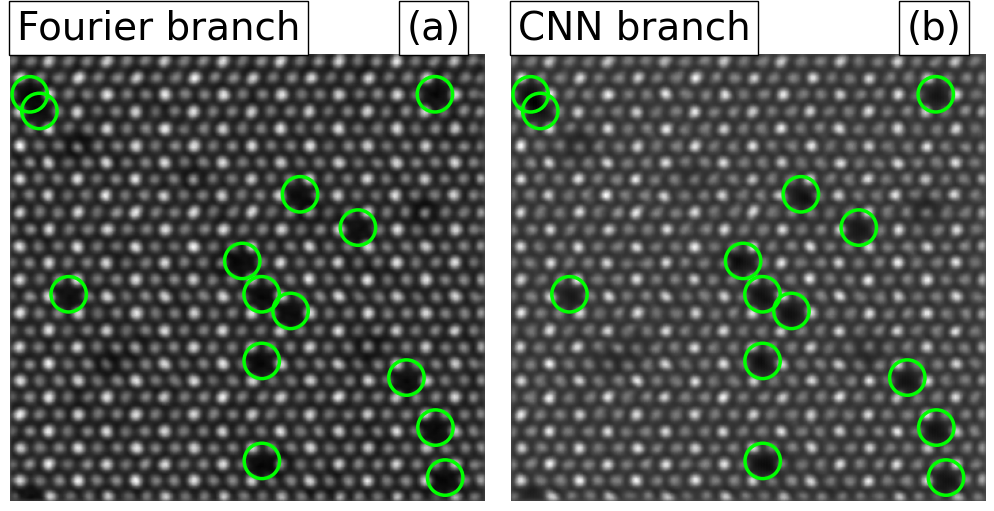

In [ ]:
from matplotlib.lines import Line2D
n = len(images[4:])
sub = 1
models = ["Fourier branch", "CNN branch"]
letters_img = ["(a)", "(b)"]

fig = plt.figure(
    figsize=(5*n, 5*sub),
    constrained_layout=True
)

gs = fig.add_gridspec(sub, n )

plt.rcParams.update({
    'font.size': 12,
    'axes.titlesize': 22
})
for idx, image in enumerate(images[4:]):
  ax_img = fig.add_subplot(gs[0, idx])
  ax_img.imshow(image, cmap='gray')
  ax_img.axis('off')

  ax_img.text(0.015, 1.1, models[idx],
            transform=ax_img.transAxes,
            fontsize=28,
            va='top',
            ha='left',
            bbox=dict(facecolor='white', edgecolor='black', boxstyle='square,pad=0.2'))

  ax_img.text(0.95, 1.1, letters_img[idx],
            transform=ax_img.transAxes,
            fontsize=28,
            va='top',
            ha='right',
            bbox=dict(facecolor='white', edgecolor='black', boxstyle='square,pad=0.2'))

  plot_vacancies_paper(ax_img, sublattice_clean, coinciding_noisy_vacancies[idx+3], coinciding_false_positives[idx+3], false_positive_vacancies[idx+3],  s_v=650, show_atoms=False)




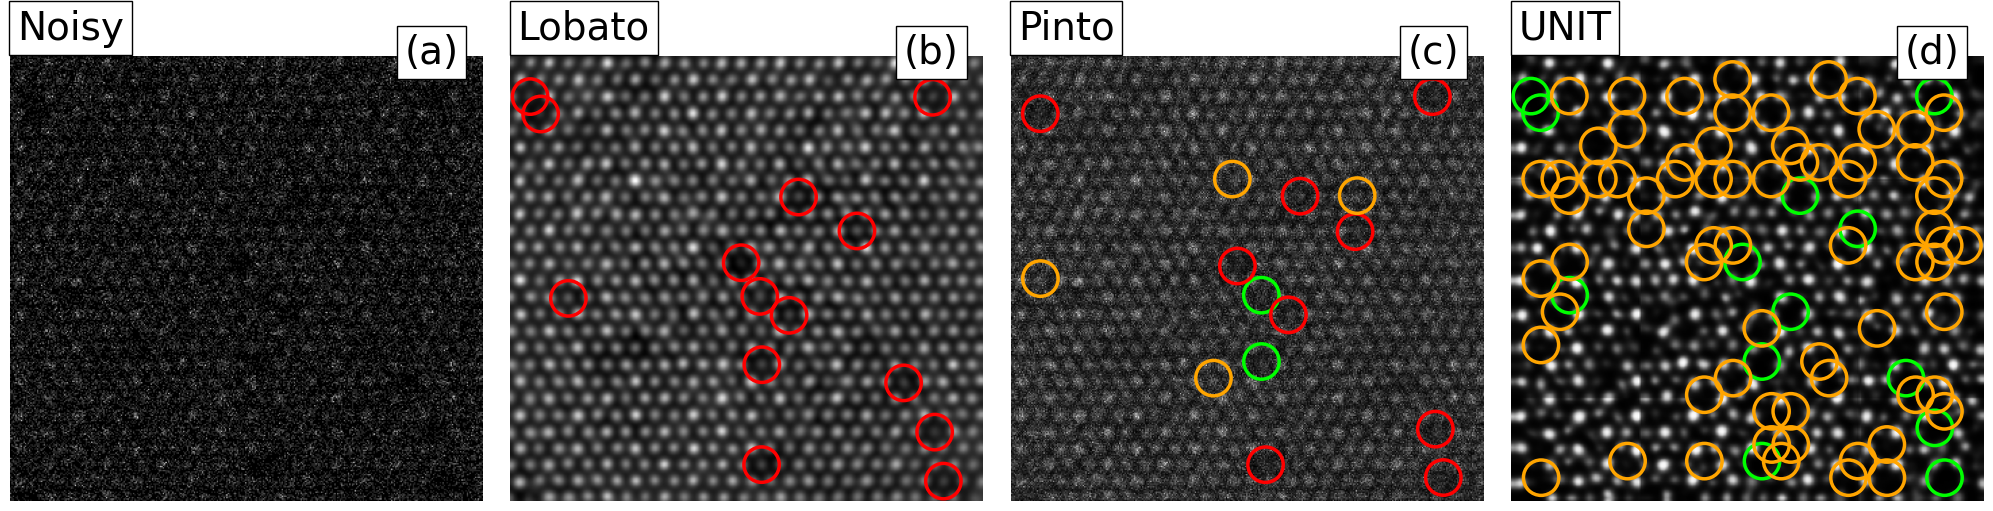

In [ ]:
dose = 250000.0
k = 2
images = []
noisy_image_path = f"/content/HAADF-STEM-image-denoising/Datasets/DATASET_graphene_vacancies/graphene-jittered_interp_0.1_dose_{dose}.tif"
lobato_image_path = f"/content/HAADF-STEM-image-denoising/Datasets/DATASET_graphene_vacancies/denoised_lobato/graphene-jittered_interp_0.1_dose_{dose}_restored_sfr_hrstem.tif"
pinto_image_path = f"/content/HAADF-STEM-image-denoising/Datasets/DATASET_graphene_vacancies/denoised_pinto/graphene-jittered_interp_0.1_dose_{dose}_denoised_pinto.tif"
unit_image_path = f"/content/HAADF-STEM-image-denoising/Datasets/DATASET_graphene_vacancies/denoised_unit_new/graphene-jittered_interp_0.1_dose_{dose}_unit_aligned.tif"
hybrid_image_path = f"/content/HAADF-STEM-image-denoising/Datasets/DATASET_graphene_vacancies/denoised_hybrid/graphene-jittered_interp_0.1_dose_{dose}_denoised_hybrid.tif"
hybrid_cnn_image_path = f"/content/HAADF-STEM-image-denoising/Datasets/DATASET_graphene_vacancies/denoised_hybrid_cnn/graphene-jittered_interp_0.1_dose_{dose}_denoised_hybrid_cnn.tif"

images.append(convert(tifffile.imread(noisy_image_path)))
images.append(convert(tifffile.imread(lobato_image_path)))
images.append(convert(tifffile.imread(pinto_image_path)))
images.append(convert(tifffile.imread(unit_image_path)))
images.append(convert(tifffile.imread(hybrid_image_path)))
images.append(convert(tifffile.imread(hybrid_cnn_image_path)))

coinciding_noisy_vacancies = [results_lobato[k][0], results_pinto[k][0], results_unit[k][0], results_hybrid[k][0], results_hybrid_cnn[k][0]]
coinciding_false_positives = [results_lobato[k][1], results_pinto[k][1], results_unit[k][1], results_hybrid[k][1], results_hybrid_cnn[k][1]]
false_positive_vacancies = [results_lobato[k][2], results_pinto[k][2], results_unit[k][2], results_hybrid[k][2], results_hybrid_cnn[k][2]]

from matplotlib.lines import Line2D
n = len(images[:4])
sub = 1
models = ["Noisy", "Lobato", "Pinto", "UNIT"]
letters_img = ["(a)", "(b)", "(c)", "(d)",]

fig = plt.figure(
    figsize=(5*n, 5*sub),
    constrained_layout=True
)

gs = fig.add_gridspec(sub, n )

plt.rcParams.update({
    'font.size': 12,
    'axes.titlesize': 22
})
for idx, image in enumerate(images[:4]):
  ax_img = fig.add_subplot(gs[0, idx])
  ax_img.imshow(image, cmap='gray')
  ax_img.axis('off')

  ax_img.text(0.015, 1.105, models[idx],
            transform=ax_img.transAxes,
            fontsize=28,
            va='top',
            ha='left',
            bbox=dict(facecolor='white', edgecolor='black', boxstyle='square,pad=0.2'))

  ax_img.text(0.95, 1.05, letters_img[idx],
            transform=ax_img.transAxes,
            fontsize=28,
            va='top',
            ha='right',
            bbox=dict(facecolor='white', edgecolor='black', boxstyle='square,pad=0.2'))

  if idx > 0:
    plot_vacancies_paper(ax_img, sublattice_clean, coinciding_noisy_vacancies[idx-1], coinciding_false_positives[idx-1], false_positive_vacancies[idx-1],  s_v=650, show_atoms=False)


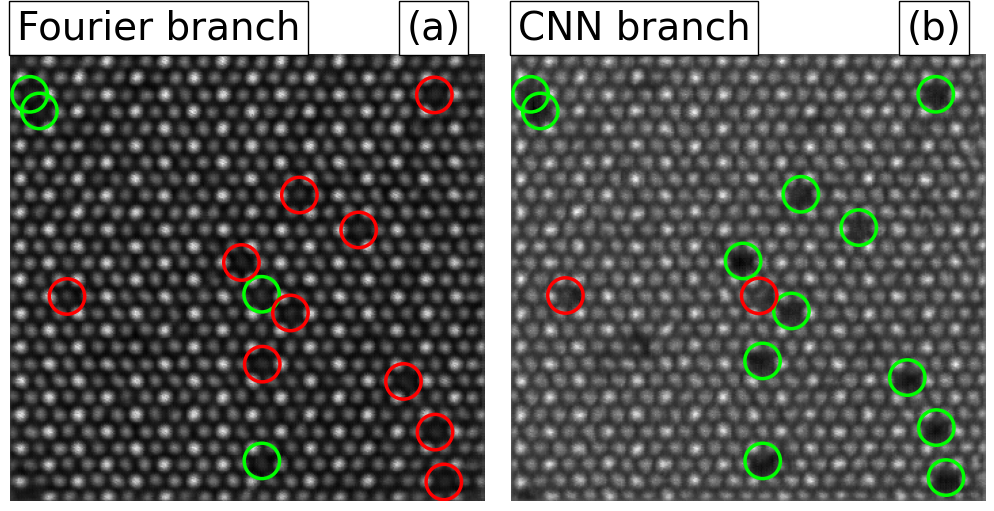

In [ ]:
from matplotlib.lines import Line2D
n = len(images[4:])
sub = 1
models = ["Fourier branch", "CNN branch"]
letters_img = ["(a)", "(b)"]

fig = plt.figure(
    figsize=(5*n, 5*sub),
    constrained_layout=True
)

gs = fig.add_gridspec(sub, n )

plt.rcParams.update({
    'font.size': 12,
    'axes.titlesize': 22
})
for idx, image in enumerate(images[4:]):
  ax_img = fig.add_subplot(gs[0, idx])
  ax_img.imshow(image, cmap='gray')
  ax_img.axis('off')

  ax_img.text(0.015, 1.1, models[idx],
            transform=ax_img.transAxes,
            fontsize=28,
            va='top',
            ha='left',
            bbox=dict(facecolor='white', edgecolor='black', boxstyle='square,pad=0.2'))

  ax_img.text(0.95, 1.1, letters_img[idx],
            transform=ax_img.transAxes,
            fontsize=28,
            va='top',
            ha='right',
            bbox=dict(facecolor='white', edgecolor='black', boxstyle='square,pad=0.2'))

  plot_vacancies_paper(ax_img, sublattice_clean, coinciding_noisy_vacancies[idx+3], coinciding_false_positives[idx+3], false_positive_vacancies[idx+3],  s_v=650, show_atoms=False)


